In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ome_arrow import OMEArrowDataset

In [2]:
ROOT = Path(
    "/mnt/hdd20tb2/virtual_staining_metric_analysis_large_outputs/pedcp90_ref"
)

fovs = pd.read_parquet(ROOT / "fovs.parquet")
images = pd.read_parquet(ROOT / "image_registry.parquet")

# Non-Metadata_* input columns are retained inside metadata_json.
metadata = pd.json_normalize(fovs["metadata_json"].map(json.loads))
for column in metadata:
    if column not in fovs:
        fovs[column] = metadata[column].to_numpy()

print(f"Available FOVs: {len(fovs)}")
print(fovs.columns.tolist())

Available FOVs: 3102
['dataset_id', 'fov_id', 'plate', 'well', 'site', 'pixel_size_um', 'Metadata_Plate', 'Metadata_Well', 'Metadata_Site', 'Metadata_AbsPositionZ', 'Metadata_ChannelID', 'Metadata_Col', 'Metadata_FieldID', 'Metadata_PlaneID', 'Metadata_PositionX', 'Metadata_PositionY', 'Metadata_PositionZ', 'Metadata_Row', 'Metadata_Reimaged', 'height', 'width', 'mask_set_id', 'metadata_json', 'FileName_OrigER', 'PathName_OrigER', 'FileName_OrigRNA', 'PathName_OrigRNA', 'FileName_OrigAGP', 'PathName_OrigAGP', 'FileName_OrigMito', 'PathName_OrigMito', 'FileName_OrigBrightfield', 'PathName_OrigBrightfield', 'FileName_OrigDNA', 'PathName_OrigDNA', 'cell_line', 'row', 'column', 'seeding_density', 'condition', 'time_point']


In [4]:
cell_col = next(
    c for c in ("cell_type", "cell_line") if c in fovs
)
density_col = next(
    c for c in ("seeding_density", "Metadata_seeding_density") if c in fovs
)

# CSV metadata may have been stored as strings.
fovs[density_col] = pd.to_numeric(fovs[density_col], errors="raise")

# Inspect the actual condition names, density values, and available FOV counts.
conditions = (
    fovs.groupby([cell_col, density_col], dropna=False)
    .size()
    .rename("n_fovs")
    .reset_index()
)
display(conditions)

,cell_line,seeding_density,n_fovs
0,A673,1000,34
1,A673,2000,36
2,A673,4000,36
3,A673,8000,36
4,A673,12000,31
...,...,...,...
85,U2-OS,1000,65
86,U2-OS,2000,69
87,U2-OS,4000,71
88,U2-OS,8000,72


In [5]:
# Initially use an existing condition; replace with your desired values.
cell_type = conditions.iloc[0][cell_col]
seeding_density = conditions.iloc[0][density_col]

matching = fovs.loc[
    fovs[cell_col].eq(cell_type)
    & fovs[density_col].eq(seeding_density)
]

selected = matching.sample(n=min(3, len(matching)), random_state=42)
display(selected[["fov_id", "plate", "well", "site", cell_col, density_col]])

,fov_id,plate,well,site,cell_line,seeding_density
980,fov_d8b55a75607965bed6c1ceeb,BR00143976,D13,7,A673,1000
1067,fov_38d56540f2539795c09d3333,BR00143976,C14,4,A673,1000
1075,fov_5913ccb0c56960731891b579,BR00143976,D14,3,A673,1000


findfont: Failed to find font weight semibold, now using 700.


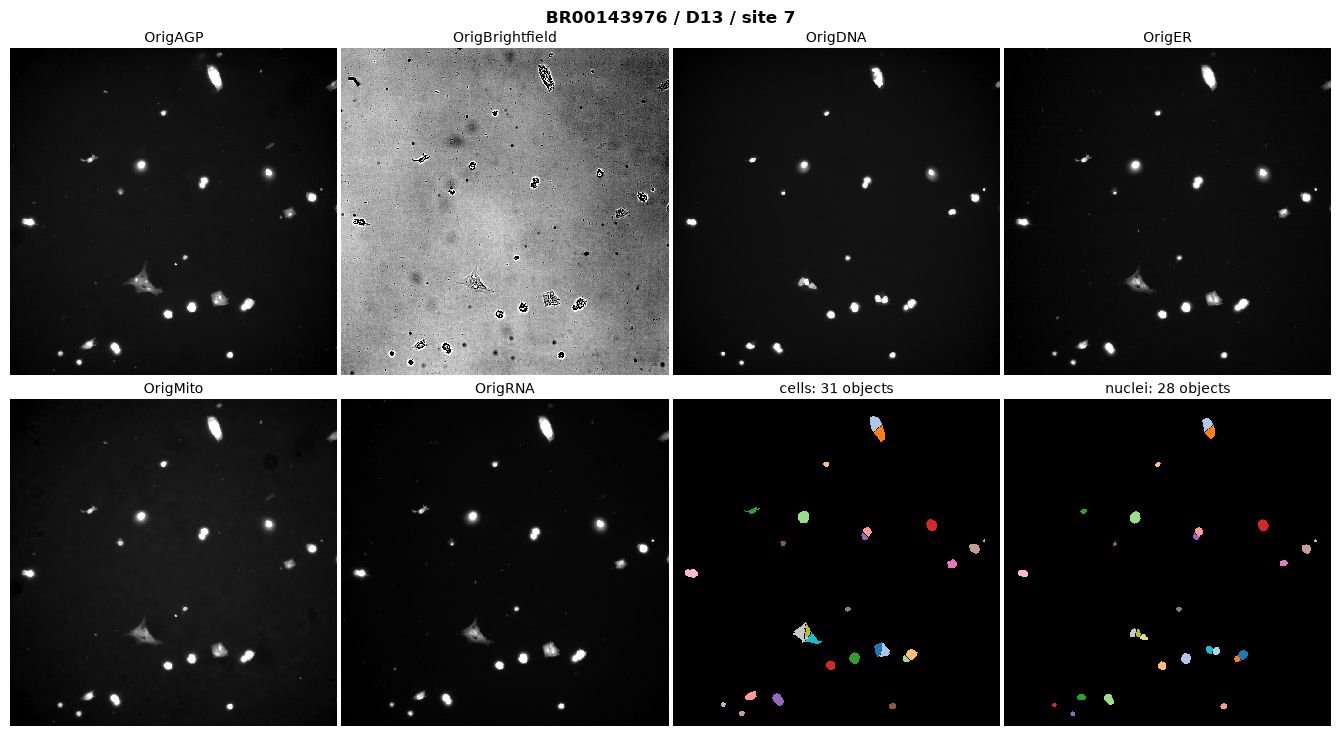

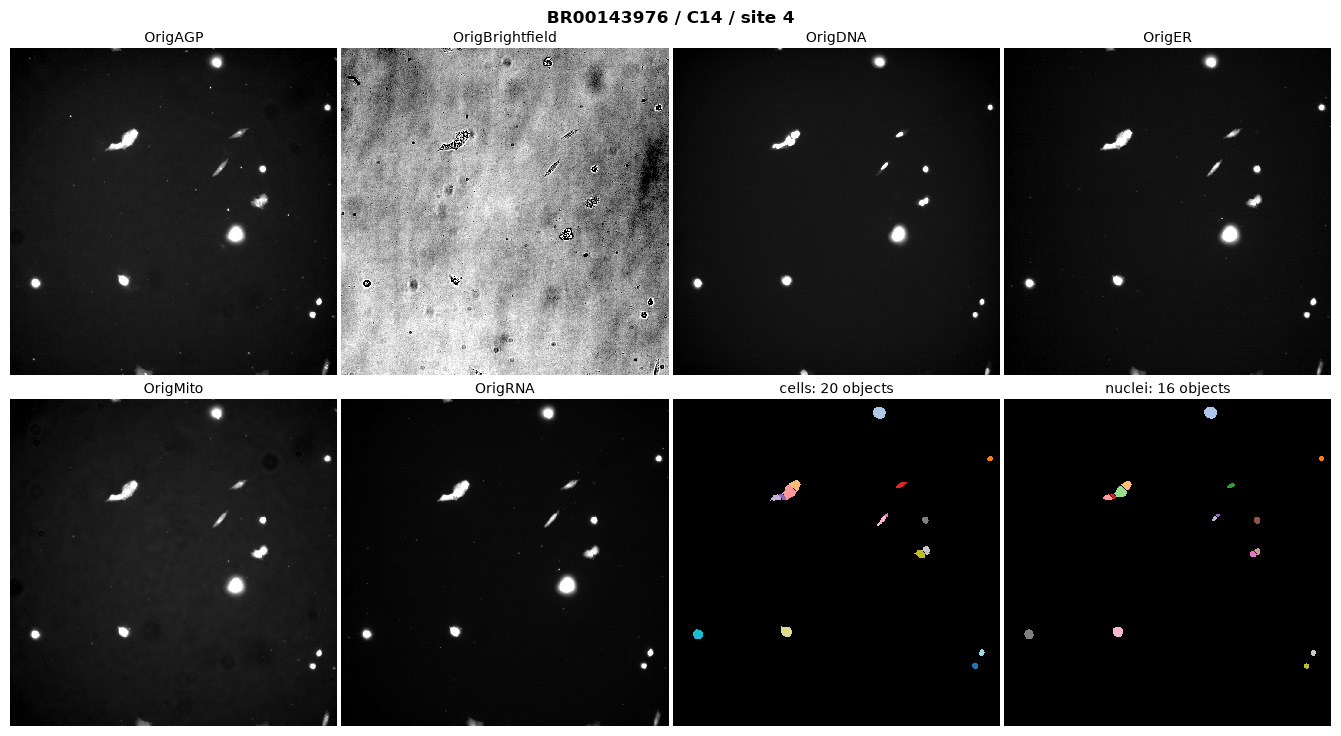

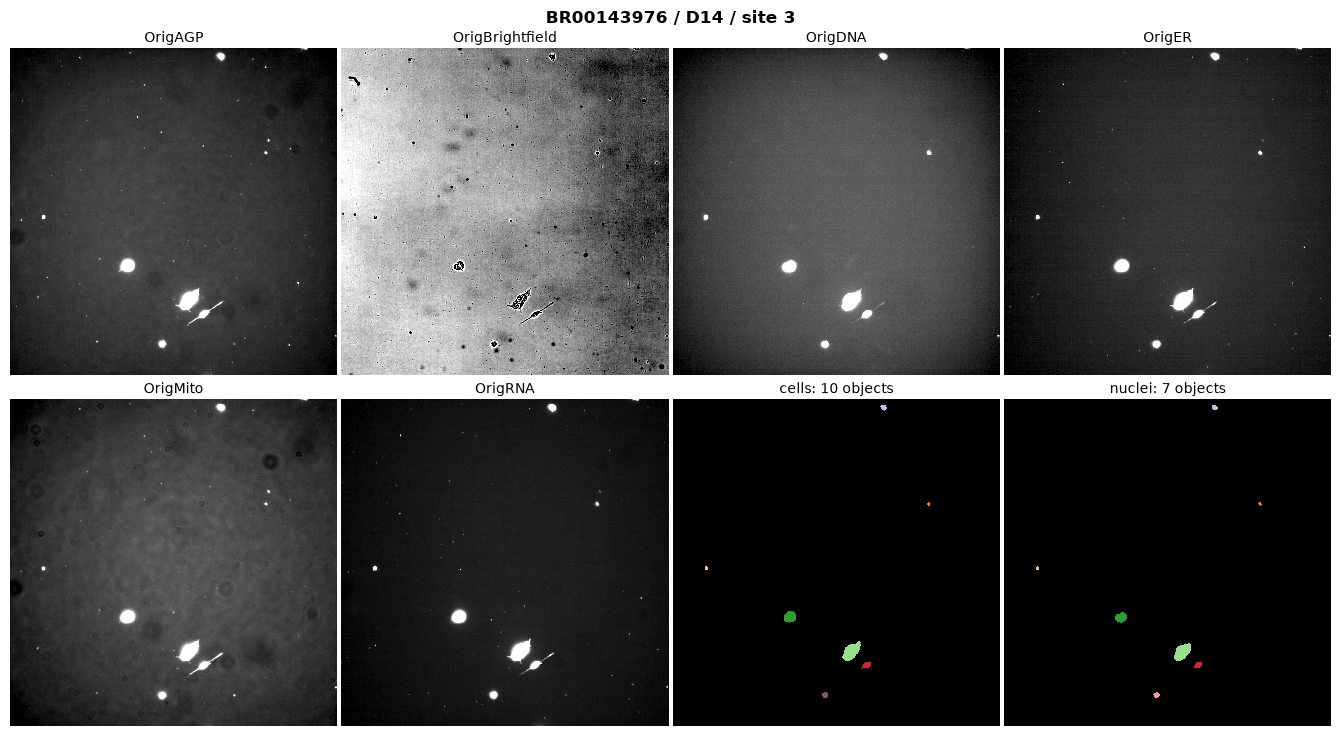

In [7]:
from matplotlib.colors import PowerNorm


# Display-only controls: gamma < 1 brightens dim structures.
CONTRAST_PERCENTILES = (1, 99.5)
DISPLAY_GAMMA = 0.7


def load_fov(fov_id):
    records = images.loc[images["fov_id"].eq(fov_id)]
    if records.empty:
        raise KeyError(fov_id)

    planes = {}
    for uri, group in records.groupby("ome_arrow_uri", sort=False):
        dataset = OMEArrowDataset(ROOT / uri)
        for row in group.itertuples(index=False):
            # Stored image axes are T, C, Z, Y, X.
            planes[(row.role, row.channel)] = (
                dataset.read_image(row.image_id)[0, 0, 0]
            )
    return planes


def show_fov(fov_id):
    planes = load_fov(fov_id)
    ncols = min(4, len(planes))
    nrows = (len(planes) + ncols - 1) // ncols
    # Compressed layout removes gaps caused by equal-aspect image axes.
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(3.6 * ncols, 3.6 * nrows),
        squeeze=False, layout="compressed",
    )
    fig.get_layout_engine().set(
        w_pad=0.02, h_pad=0.02, wspace=0.01, hspace=0.02,
    )

    label_cmap = plt.get_cmap("tab20").copy()
    label_cmap.set_bad("black")

    for ax, ((role, channel), array) in zip(axes.flat, planes.items()):
        if role == "labels":
            # Cycle instance colors; background stays black.
            colors = np.ma.masked_where(array == 0, (array % 20).astype(float))
            ax.imshow(
                colors, cmap=label_cmap, vmin=0, vmax=19,
                interpolation="nearest",
            )
            title = f"{channel}: {np.count_nonzero(np.unique(array))} objects"
        else:
            # Scale each channel independently; stored pixels are unchanged.
            finite = array[np.isfinite(array)]
            if finite.size:
                lo, hi = np.percentile(finite, CONTRAST_PERCENTILES)
                if hi <= lo:
                    lo, hi = float(finite.min()), float(finite.max())
            else:
                lo, hi = 0.0, 1.0
            ax.imshow(
                np.ma.masked_invalid(array), cmap="gray",
                norm=PowerNorm(
                    gamma=DISPLAY_GAMMA, vmin=lo,
                    vmax=hi if hi > lo else lo + 1, clip=True,
                ),
                interpolation="nearest",
            )
            title = channel

        ax.set_title(title, fontsize=10, pad=4)
        ax.axis("off")

    for ax in list(axes.flat)[len(planes):]:
        ax.set_visible(False)

    row = fovs.loc[fovs["fov_id"].eq(fov_id)].iloc[0]
    fig.suptitle(
        f"{row['plate']} / {row['well']} / site {row['site']}",
        fontsize=12, fontweight="semibold",
    )
    plt.show()


for fov_id in selected["fov_id"]:
    show_fov(fov_id)